![Python Banner](../../Image/05_04_doubleML.png)


# 4.6 Weighted Double Machine Learning

Weighted DML puts a weight $\omega$ into the orthogonal score so the target is not the average effect in the whole sample. $\omega = 1$ is the ordinary ATE. $\omega = 1\{G = k\}$ is the effect in group $k$. Inverse-propensity weights target the effect on the treated.

The same idea shows up when raw rows have been collapsed to segments with frequency weights. Fitting on the raw sample is the expanded version of that table. Multiplying the doubly robust scores by $\omega$ answers the weighted estimand directly. This notebook generates a binary design with a known segment effect, fits `LinearDML`, and reweights the scores from `InteractiveRegressionDML`.


## Overview

For a binary treatment the doubly robust score $\psi_i$ has mean equal to the ATE. A weighted estimand is

$$\hat\theta_\omega = \frac{\sum_i \omega_i \psi_i}{\sum_i \omega_i}.$$

Cross-fitting does not change. The weight only changes which rows the final average emphasizes.

| Weight | Estimand |
|--------|----------|
| $\omega = 1$ | ATE |
| $\omega = 1\{A = 1\}$ | Effect in the $A = 1$ segment |
| $\omega = 1\{A = 0\}$ | Effect in the $A = 0$ segment |


## Set Up


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
data_dir = root / "Data"
if not data_dir.is_dir():
    raise FileNotFoundError(
        "The Data directory was not found. It should sit next to pyproject.toml."
    )

try:
    import pycausalml  # noqa: F401
    print("PyCausalML ready.")
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot]"],
    )
    print("PyCausalML installed.")
print("Data directory:", data_dir)


PyCausalML ready.
Data directory: /home/zia207/Github/PyCausalML/Data


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import (
    GradientBoostingClassifier,
    GradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.linear_model import Lasso, LassoCV, LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    mean_squared_error,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

from pycausalml import (
    CausalForestDML,
    InteractiveRegressionDML,
    KernelDML,
    LinearDML,
    NonParamDML,
    PartiallyLinearDML,
    SparseLinearDML,
    explain_cate,
)
from pycausalml.interpretation import plot_cate_hist

plt.rcParams["figure.dpi"] = 110
print("Imported PyCausalML")


Imported PyCausalML


### Generating the sample

Binary features. Column $A$ shifts the propensity and sets the true effect $\theta = -1 + 2A$: the effect is $-1$ when $A = 0$ and $+1$ when $A = 1$. The other columns are controls. Errors are heteroskedastic in $A$.


In [3]:
rng = np.random.default_rng(123)
n, p = 6000, 10
X_raw = rng.binomial(1, 0.5, size=(n, p)).astype(float)
propensity = 1.0 / (1.0 + np.exp(-(X_raw[:, 1] - 0.5)))
treatment = rng.binomial(1, propensity).astype(float)
theta = -1.0 + 2.0 * X_raw[:, 1]
noise = rng.normal(scale=1.0 + X_raw[:, 1], size=n)
outcome = theta * treatment + X_raw[:, 1] + noise
names = ["A", "B", "C", "D"] + [f"W{j}" for j in range(1, 6)]
X = X_raw[:, 1:]
print("True effect when A=1: 1 ; when A=0: -1")
pd.DataFrame(X, columns=names).head()


True effect when A=1: 1 ; when A=0: -1


,A,B,C,D,W1,W2,W3,W4,W5
0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0
1,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0
2,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0
3,1.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0
4,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


## Applying LinearDML

`LinearDML` is fit on the raw rows. That is the frequency-weighted segment table written out one row per observation.


In [4]:
est = LinearDML(discrete_treatment=True, n_splits=3, model_y="rf", n_estimators=40, random_state=123)
est.fit(X, treatment, outcome, feature_names=names)
print(est.average_treatment_effect())


{'estimate': 0.0590134092519285, 'std.err': 0.04184663671951373, 'ci_lower': -0.023004491592449765, 'ci_upper': 0.14103131009630676}


### Treatment effect in one segment

The segment $A=1, B=0, C=0, D=0$ has true effect $+1$. Controls are set to their sample means. `confidence_interval` is the interval for the average effect, not a pointwise band for that one row.


In [5]:
means = X.mean(axis=0)
segment = means.copy()
segment[:4] = np.array([1.0, 0.0, 0.0, 0.0])
print("CATE at A=1, B=C=D=0:", round(float(est.predict(segment.reshape(1, -1))[0]), 4))
print("ATE interval:", est.confidence_interval())


CATE at A=1, B=C=D=0: 1.1709
ATE interval: (-0.023004491592449765, 0.14103131009630676)


### Coefficients


In [6]:
print("Intercept:", round(float(est.intercept_), 4))
pd.DataFrame({"feature": names, "coef": est.feature_coef_}).round(4)


Intercept: -1.046


,feature,coef
0,A,2.1248
1,B,-0.0333
2,C,-0.0202
3,D,-0.0803
4,W1,0.0635
5,W2,0.0011
6,W3,0.0750
7,W4,-0.0438
8,W5,0.0882


## Weighted scores

`InteractiveRegressionDML` stores the doubly robust score on `influence_`. The ATE is its mean. The segment effects are the means inside $A=1$ and $A=0$.


In [7]:
irm = InteractiveRegressionDML(n_splits=3, model_y="rf", n_estimators=40, random_state=123)
irm.fit(X, treatment, outcome, feature_names=names)
psi = irm.influence_
print("Doubly robust ATE:", round(float(np.mean(psi)), 4))
print("A=1 segment:", round(float(np.mean(psi[X[:, 0] == 1])), 4), "(true 1)")
print("A=0 segment:", round(float(np.mean(psi[X[:, 0] == 0])), 4), "(true -1)")


Doubly robust ATE: 0.0577
A=1 segment: 1.1067 (true 1)
A=0 segment: -1.0255 (true -1)


## Polynomial CATE

`SparseLinearDML` on a degree-2 expansion of $A,B,C,D$. The true effect is linear in $A$, so the extra terms should stay small, and the segment prediction should stay near $+1$.


In [8]:
poly = PolynomialFeatures(degree=2, include_bias=False)
modifiers = poly.fit_transform(X[:, :4])
poly_names = [f"p{j}" for j in range(modifiers.shape[1])] + names[4:]
X_poly = np.column_stack([modifiers, X[:, 4:]])
sparse = SparseLinearDML(
    discrete_treatment=True, n_splits=2, model_y="rf", n_estimators=30, alpha=0.01, random_state=7,
)
sparse.fit(X_poly, treatment, outcome, feature_names=poly_names)
seg_row = np.column_stack([poly.transform(np.array([[1.0, 0.0, 0.0, 0.0]])), means[4:].reshape(1, -1)])
print(sparse.average_treatment_effect())
print("Polynomial CATE at the segment:", round(float(sparse.predict(seg_row)[0]), 4))
print("Intercept", round(float(sparse.intercept_), 4))


{'estimate': 0.09474540729498593, 'std.err': 0.041967352449671515, 'ci_lower': 0.012490907967130954, 'ci_upper': 0.1769999066228409}
Polynomial CATE at the segment: 1.0082
Intercept -0.8484


## Random-forest final stage

`CausalForestDML` lets the CATE be a step function. The two modes should sit near $-1$ and $+1$.


{'estimate': 0.052128048269594635, 'std.err': 0.04423923256036371}


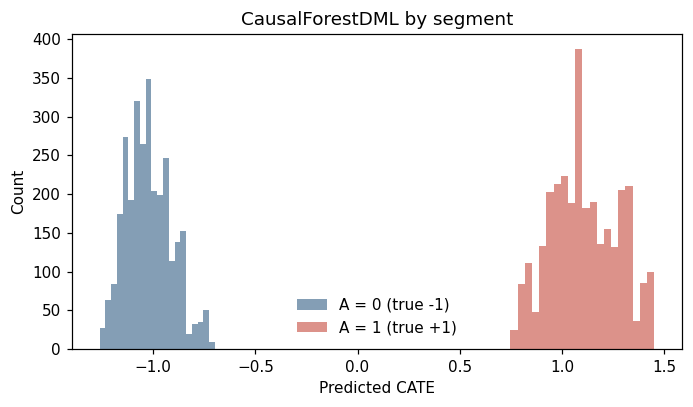

In [9]:
forest = CausalForestDML(num_trees=60, n_splits=2, random_state=9)
forest.fit(X, treatment, outcome, feature_names=names)
cate = forest.predict(X)
print(forest.average_treatment_effect())
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.hist(cate[X[:, 0] == 0], bins=20, alpha=0.55, label="A = 0 (true -1)", color="#1F4E79")
ax.hist(cate[X[:, 0] == 1], bins=20, alpha=0.55, label="A = 1 (true +1)", color="#C0392B")
ax.set_xlabel("Predicted CATE")
ax.set_ylabel("Count")
ax.set_title("CausalForestDML by segment")
ax.legend(frameon=False)
fig.tight_layout()


## Summary

The orthogonal score, averaged with a weight, is the weighted estimand. On this design $1\{A=1\}$ recovers $+1$ and $1\{A=0\}$ recovers $-1$. `LinearDML` reports the same structure as coefficients. `CausalForestDML` recovers it as two clumps in the CATE distribution.

## Resources

- Chernozhukov, V., et al. (2018). Double/debiased machine learning for treatment and structural parameters. *The Econometrics Journal*, 21(1), C1–C68.
- PyCausalML: `LinearDML`, `SparseLinearDML`, `InteractiveRegressionDML`, `CausalForestDML`.
